<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/04_Botnet_DGA_Detection/HybridQNN_BotnetDGA_Suryotrisongko2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical deep learning for botnet DGA detection: Suryotrisongko and Musashi (2022) step by step

> H. Suryotrisongko and Y. Musashi, "Evaluating hybrid quantum-classical deep learning for cybersecurity botnet DGA detection",
> *Procedia Computer Science* 197 (2022) 223-229 (Sixth Information Systems International Conference, ISICO 2021).
> https://doi.org/10.1016/j.procs.2021.12.135

**What this notebook does.** The paper puts a small *quantum layer* (a PennyLane circuit) between the Dropout layer and the output layer of a
Keras network that decides whether a domain name was produced by a **domain generation algorithm (DGA)**, i.e. whether it belongs to a botnet.
Six circuits are compared (two ways to load numbers into qubits times three trainable circuit templates) against the same network
**without** the quantum layer, with 100, 1,000 and 10,000 training/test samples, with fixed random seeds, and finally under the noise of eight
IBM quantum computers. We rebuild every one of those experiments, train a classical baseline on exactly the same inputs, add a random forest and
an RBF-SVM as sanity checks, and finish with a claim-by-claim comparison of our numbers with the paper's.

**How to run it.** Open it in Colab (badge above), choose a *CPU* runtime and use *Runtime -> Run all*. With `FAST_MODE = True` (default) the whole
notebook finishes in about 10 minutes; set `FAST_MODE = False` in the configuration cell for the paper's four runs per size, all three
sample sizes and all eight devices (about 45-60 minutes on a 2-core CPU). The data are downloaded automatically.

**What you get at the end.** The paper's Tables 1, 2 and 3 re-computed with our code, the training curves, confusion matrices, the noise heat-map,
a validation of our fast noise simulator against PennyLane and Qiskit Aer, and a table that says for each claim of the paper whether we
*reproduced* it, *did not reach* it, or *cannot check* it. Short version of what we find: the idea works (the hybrid network classifies DGA domains
well) but it is not better than the same network without the quantum layer, and many of the paper's most striking numbers depend on tiny test sets
(19 test samples at n = 100) and on the random seed.

## 0. The paper in one page

**Problem.** Botnets hide their command-and-control servers behind domain names that an algorithm (a *DGA*) generates by the thousand, so
blacklists fail. The paper asks a *machine-learning* question: can a quantum circuit, used as a layer inside a deep network, help to separate
DGA domains from benign ones, and does it survive realistic quantum noise?

**Decision.** Binary classification of a domain name: benign (Alexa top-1M style names) versus DGA (ten botnet families).

**Data.** The *Botnet DGA Dataset* of the same authors (IEEE DataPort, doi 10.21227/rg6z-z622): 1,803,333 domain names turned into numerical features
(entropy, relative entropy to Alexa and to the botnet families, Jensen-Shannon "IRad", character length, a decision-tree feature, an n-gram reputation).
Only **four features** are used: `MinREBotnets`, `CharLength`, `TreeNewFeature`, `nGramReputation_Alexa`.

**Preprocessing.** Random sample of n = 100, 1,000 or 10,000 names; `train_test_split` (shuffled); standardise; clip to [-5, 5].

**Model.** A Keras sequential network: `Dense` layers with ReLU, `Dropout`, **a PennyLane quantum layer**, `Dense(1)` with sigmoid. The quantum layer is
an *embedding* (Angle or IQP) followed by a trainable *template* (BasicEntanglerLayers, RandomLayers or StronglyEntanglingLayers), giving six
variants #1-#6; its outputs are Pauli-Z expectation values. The classical counterpart is the same network without the quantum layer.

**Experiments and claims.**
1. *Table 1:* four unseeded runs for each n and each variant. Best hybrid accuracy 94.7 % (n = 100) and 93.9 % (n = 1,000); on average the hybrid is **worse**
   than the classical network (classical average 85.5 / 93.8 / 89.5 % for n = 100 / 1,000 / 10,000), except in a few runs.
2. *Table 2:* with a fixed initial seed (3, 123, 395) the accuracy repeats exactly, but it differs strongly between seeds, so comparisons must use identical seeds.
3. *Table 3:* with the noise models of eight IBM devices (`qiskit.aer` device of the PennyLane-Qiskit plug-in, n = 100, seed 123) the combination
   **Angle Embedding + StronglyEntanglingLayers** is best: maximum 94.7 %, average 91.4 %, above the classical average (85.5 %) at n = 100.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | full 1,803,333-row Botnet DGA Dataset (IEEE DataPort, login needed) | the authors' public **5,001-row random sample** (Azure blob, also used in QC-002); all sample sizes are drawn from it |
| Sample sizes | n = 100, 1,000, 10,000 | n = 100, 1,000 as in the paper; **n = 5,001 (the whole sample) replaces n = 10,000** (full mode only; FAST mode skips it) |
| Test-set size | not stated; the accuracies in the paper are multiples of 1/19 (n = 100) and 1/197 (n = 1,000) | test fraction 0.197 (19 / 197 / 985 test samples), shuffled, not stratified |
| Features / scaling | 4 features, standardise + clip [-5, 5] | same; the scaler is fitted on the **training split only** (no leakage) |
| Classical layers | "Dense layers with ReLU, Dropout, Dense sigmoid" (sizes in Fig. 1, not in the text) | `Dense(8, relu) -> Dense(4, relu) -> Dropout(0.2) -> Dense(1, sigmoid)`; Glorot-uniform weights, zero biases (the Keras defaults) |
| Quantum layer | between Dropout and the last Dense; qubits not stated | **4 qubits** (one per feature), 2 template layers, 4 Pauli-Z expectation values as output |
| Embeddings / templates | Angle, IQP / BasicEntangler, Random, StronglyEntangling | the same PennyLane templates; `RandomLayers` with PennyLane's default seed 42 (fixed structure, trainable angles) |
| Quantum weights init | not stated (KerasLayer default) | U(-0.05, 0.05), the Keras `uniform` default |
| Framework | Keras / TensorFlow + PennyLane `KerasLayer` | **PyTorch** + PennyLane `TorchLayer` (TensorFlow/Keras 3 does not support `KerasLayer` any more); same architecture |
| Optimiser, loss, epochs, batch | not stated | Adam, lr 0.01, binary cross-entropy; epochs / batch size in the configuration cell (n = 100: 40 epochs, batch 16) |
| Unseeded runs (Table 1) | 4 runs per size, no seed | 4 runs with seeds 42-45; hybrid and classical share each run's data split |
| Simulator | `default.qubit`; noise via `qiskit.aer` device of PennyLane-Qiskit | `default.qubit` for the ideal runs; for the noise study a **small density-matrix simulator** with noise read from fake IBM backends, validated against Qiskit Aer (section 8) |
| Hardware | eight IBM devices, as *noise models* only | `FakeMelbourneV2, FakeYorktownV2, FakeAthensV2, FakeBelemV2, FakeLimaV2, FakeQuitoV2, FakeSantiagoV2`; `ibmqx2` -> `FakeEssexV2` (Yorktown is the same chip) |
| Baselines | classical DL only | classical DL + random forest + RBF-SVC on identical inputs |
| Metrics | accuracy only | accuracy (as in the paper) plus precision, recall, F1 (DGA = positive), confusion matrices, timings |

Everything we had to invent is marked `# CHOICE:` in the code.

## 1. Setup

The next cell installs pinned versions on Colab (and does nothing on a machine that already has them); the following cell holds **every tunable constant**.
`FAST_MODE` shrinks the budgets for a class demo. Because the paper never states epochs, batch size, optimiser or layer sizes, those numbers are our
choices (fixed once, before looking at test results, using only validation splits of the training data).

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The pip line runs on Colab (or wherever PennyLane / Qiskit are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("qiskit_aer") is None:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane and Qiskit already present; skipping pip install.")

PennyLane and Qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False     # True: class demo (about 10 minutes on a CPU). False: the paper's four runs per size and all eight devices (about 45-60 minutes).
SEED      = 42        # master seed; run r of the "unseeded" Table-1 experiment uses SEED + r
IBM_TOKEN = ""        # optional: a real IBM Quantum token enables the (untested) hardware cell at the end of section 8; leave empty to skip

# ---- data -------------------------------------------------------------------------------------------------------
DATA_DIR  = "dga_data"                                    # downloaded files are cached here
URL_5000  = "https://dgadata.blob.core.windows.net/dga/BotnetDgaDataset_5000_newMethod.csv"      # 5,001 rows, 7 features + label
URL_1000  = "https://aq5efd7d2644dd406cb3ec2d.blob.core.windows.net/dga/BotnetDgaDataset_1000.csv"  # 1,000 rows (fallback pool)
FEATURES  = ["MinREBotnets", "CharLength", "TreeNewFeature", "nGramReputation_Alexa"]   # the four features of the paper (Sec. 3.3)
TEST_FRAC = 0.197     # CHOICE: the paper's accuracies are multiples of 1/19 (n=100) and 1/197 (n=1000), so the test set is about 19.7 % of n
CLIP      = 5.0       # paper: standardise, then clip to [-5, 5]

# ---- model (the paper does not give these; see the table in section 0) -------------------------------------------
N_QUBITS  = 4         # CHOICE: one qubit per feature (the quantum layer must receive as many numbers as it has qubits)
HIDDEN    = (8, 4)    # CHOICE: Dense(8, relu) -> Dense(4, relu) -> Dropout -> [quantum layer] -> Dense(1, sigmoid)
DROPOUT   = 0.2       # CHOICE
N_Q_LAYERS = 2        # CHOICE: repetitions of the entangling template
Q_INIT    = 0.05      # CHOICE: quantum weights ~ U(-0.05, 0.05), the Keras 'uniform' default that PennyLane's KerasLayer uses
RANDOM_LAYERS_SEED = 42   # PennyLane's default seed for the random gate choice of RandomLayers (fixed structure, trainable angles)
LR        = 0.01      # CHOICE: Adam learning rate (binary cross-entropy loss)

# ---- budgets ----------------------------------------------------------------------------------------------------
if FAST_MODE:
    SIZES     = [100, 1000]                 # n = 10,000 of the paper is not available (see section 1) -> skipped in FAST mode
    N_RUNS    = 2                           # paper: 4 unseeded runs per size
    EPOCHS    = {100: 15, 1000: 6}          # CHOICE
    BATCH     = {100: 16, 1000: 32}         # CHOICE
    SEEDS_T2  = [3, 123]                    # paper: 3, 123, 395
    REPEAT_T2 = [3]                         # ansatz that are run twice to test "same seed -> same accuracy"
    N_DEVICES = 2                           # noise models of the first 2 devices of the list
else:
    SIZES     = [100, 1000, 5001]           # 5001 = the whole sample file, standing in for the paper's n = 10,000
    N_RUNS    = 4
    EPOCHS    = {100: 40, 1000: 25, 5001: 20}
    BATCH     = {100: 16, 1000: 32, 5001: 128}
    SEEDS_T2  = [3, 123, 395]
    REPEAT_T2 = [1, 3, 4]                   # CHOICE: three of the six ansatz are repeated (the paper repeated all; determinism is the same claim)
    N_DEVICES = 8
EPOCHS_NOISE, BATCH_NOISE, SEED_NOISE, N_NOISE = EPOCHS[100], BATCH[100], 123, 100   # paper's Table 3: n = 100, seed 123
print("FAST_MODE =", FAST_MODE, "| sizes", SIZES, "| runs", N_RUNS, "| epochs", EPOCHS)

FAST_MODE = False | sizes [100, 1000, 5001] | runs 4 | epochs {100: 40, 1000: 25, 5001: 20}


In [3]:
import os, time, random, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import qiskit, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import qiskit_ibm_runtime.fake_provider as fake_provider

warnings.filterwarnings("ignore")
torch.set_num_threads(min(4, os.cpu_count() or 1))     # tiny circuits: more threads do not help much; keep the machine shared-friendly
os.makedirs(DATA_DIR, exist_ok=True)

def seed_everything(seed):
    """Seed every random number generator the experiments touch (Python, NumPy, PyTorch)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

seed_everything(SEED)
rng = np.random.default_rng(SEED)
print("pennylane", qml.__version__, "| torch", torch.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

pennylane 0.45.1 | torch 2.14.1+cpu | qiskit 2.5.2 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 2. The data: the authors' public sample of the Botnet DGA Dataset

The full dataset sits behind an IEEE DataPort login. The authors also published a random sample of it on public Azure storage (the same files their
QHTC paper, QC-002 in this repository, uses). We download it and cache it in `DATA_DIR`. Each row is one domain name, already turned into numbers; label 0 =
benign, label 1 = DGA. From the seven columns we keep the four named in the paper.

Why a *sample of a sample* is fine here: the paper itself only ever uses n = 100, 1,000 or 10,000 random rows of the 1.8 million, so the only thing we
lose is the n = 10,000 setting, which we replace by "all 5,001 rows" in the full run.

In [4]:
COLS = ["Entropy", "REAlexa", "MinREBotnets", "InformationRadius", "CharLength", "TreeNewFeature", "nGramReputation_Alexa", "Result"]

def fetch(url, path):
    if not os.path.exists(path):
        r = requests.get(url, timeout=120); r.raise_for_status()
        with open(path, "wb") as f: f.write(r.content)
        print("downloaded", os.path.basename(path), f"({len(r.content)/1e3:.0f} kB)")
    else:
        print("using cached", os.path.basename(path))
    return path

def load_pool():
    """The 5,001-row sample of the IEEE Botnet DGA Dataset; fallback: the 1,000-row sample; or a file you put into DATA_DIR."""
    p5 = os.path.join(DATA_DIR, "BotnetDgaDataset_5000_newMethod.csv")
    try:
        fetch(URL_5000, p5)
        df = pd.read_csv(p5, encoding="utf-8-sig")          # the file starts with a byte-order mark
        df.columns = COLS
        return df, "5000-row sample"
    except Exception as e:
        print(f"5000-row file unavailable ({type(e).__name__}); # CHOICE: falling back to the 1000-row sample")
    p1 = os.path.join(DATA_DIR, "BotnetDgaDataset_1000.csv")
    fetch(URL_1000, p1)
    return pd.read_csv(p1, header=None, skiprows=1, names=COLS), "1000-row sample"     # first line is a "1000,7,benign,dga" header

POOL, POOL_NAME = load_pool()
POOL = POOL.reset_index(drop=True)
print(f"\nPool = {POOL_NAME}: {POOL.shape[0]} rows, {POOL['Result'].mean()*100:.1f} % DGA (label 1), {POOL['Result'].isna().sum()} missing labels, "
      f"{POOL.duplicated().sum()} duplicated rows (kept, as the paper did not mention removing any)")
SIZES = sorted({min(n, len(POOL)) for n in SIZES})          # if only the 1000-row fallback is available, the larger sizes collapse onto it
display(POOL[FEATURES + ["Result"]].describe().T.round(3))

using cached BotnetDgaDataset_5000_newMethod.csv

Pool = 5000-row sample: 5001 rows, 44.8 % DGA (label 1), 0 missing labels, 31 duplicated rows (kept, as the paper did not mention removing any)


,count,mean,std,min,25%,50%,75%,max
MinREBotnets,5001.0,1.288,0.571,0.194,0.868,1.229,1.610,5.08
CharLength,5001.0,17.160,6.778,5.000,12.000,16.000,20.000,41.00
TreeNewFeature,5001.0,0.444,0.335,0.002,0.107,0.353,0.829,0.99
nGramReputation_Alexa,5001.0,81.337,54.066,3.557,39.435,64.663,110.882,314.29
Result,5001.0,0.448,0.497,0.000,0.000,0.000,1.000,1.00


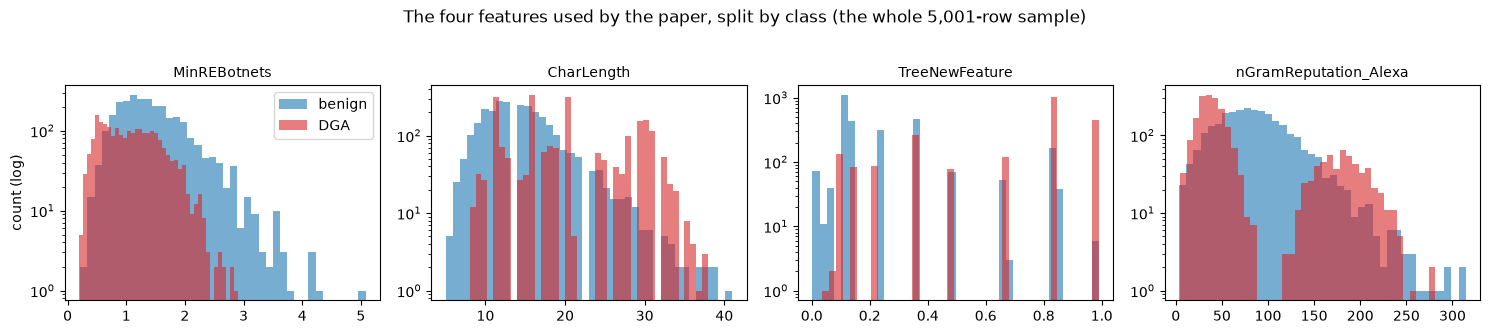

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, f in zip(axes, FEATURES):
    for c, col, lab in [(0, "tab:blue", "benign"), (1, "tab:red", "DGA")]:
        ax.hist(POOL.loc[POOL.Result == c, f], bins=40, alpha=0.6, color=col, label=lab)
    ax.set_title(f, fontsize=10); ax.set_yscale("log")
axes[0].legend(); axes[0].set_ylabel("count (log)")
plt.suptitle("The four features used by the paper, split by class (the whole 5,001-row sample)", y=1.03); plt.tight_layout(); plt.show()

## 3. Sampling, splitting, standardising and clipping

For every experiment we (1) draw n random rows, (2) split them with a shuffled `train_test_split`, (3) standardise using **training statistics only**, and
(4) clip to [-5, 5], exactly the paper's recipe. The test set is about 19.7 % of n: that fraction reproduces the paper's accuracy values, which are all
multiples of 1/19 at n = 100 (42.1 % = 8/19, 94.7 % = 18/19) and of 1/197 at n = 1,000. **Consequence:** at n = 100 one test sample is worth 5.3 accuracy
points, so a difference of "one sample" is already larger than our 2-point tolerance. Keep that in mind when reading every verdict below.

In [6]:
def prepare(n, seed):
    """Random sample of n rows -> shuffled train/test split -> standardise (fit on TRAIN only) -> clip to [-CLIP, CLIP]."""
    n = min(n, len(POOL))
    r = np.random.default_rng(seed)
    d = POOL.iloc[r.choice(len(POOL), size=n, replace=False)]
    X, y = d[FEATURES].values.astype(float), d["Result"].values.astype(int)
    n_test = max(int(TEST_FRAC * n), 1)                                   # n=100 -> 19, n=1000 -> 197, as implied by the paper's accuracies
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=n_test, random_state=seed)   # paper: shuffled split (no stratification)
    sc = StandardScaler().fit(Xtr)                                        # no leakage: statistics from the training split only
    Xtr = np.clip(sc.transform(Xtr), -CLIP, CLIP); Xte = np.clip(sc.transform(Xte), -CLIP, CLIP)
    return Xtr.astype(np.float32), Xte.astype(np.float32), ytr, yte

for n in SIZES[:3]:
    Xtr, Xte, ytr, yte = prepare(n, SEED)
    print(f"n={n:5d}: train {Xtr.shape[0]:5d} / test {Xte.shape[0]:4d} | test share of DGA {yte.mean()*100:5.1f} % | "
          f"one test sample is worth {100/len(yte):.2f} accuracy points | feature range after clipping [{Xtr.min():.2f}, {Xtr.max():.2f}]")

n=  100: train    81 / test   19 | test share of DGA  36.8 % | one test sample is worth 5.26 accuracy points | feature range after clipping [-1.65, 2.86]
n= 1000: train   803 / test  197 | test share of DGA  46.7 % | one test sample is worth 0.51 accuracy points | feature range after clipping [-1.78, 5.00]
n= 5001: train  4016 / test  985 | test share of DGA  43.8 % | one test sample is worth 0.10 accuracy points | feature range after clipping [-1.92, 5.00]


## 4. The quantum layer: six circuits

A quantum layer takes a vector of four numbers (the outputs of the previous Dense layer), loads them into a 4-qubit circuit (**embedding**), applies
trainable gates (**template**) and returns the expectation value of Pauli-Z on each qubit (four numbers in [-1, 1]) to the next layer. PennyLane makes this
a differentiable `TorchLayer`, so the circuit angles are trained by back-propagation together with the classical weights.

* **Angle embedding**: qubit i is rotated by RX(x_i).
* **IQP embedding** (Havlicek et al. 2019): Hadamards, RZ(x_i) and ZZ-interactions with angles x_i x_j, so features interact before any training.
* **BasicEntanglerLayers**: one RX rotation per qubit plus a ring of CNOTs, per layer.
* **RandomLayers**: randomly chosen rotations and two-qubit gates (the random choice is fixed by a seed; the angles are trained).
* **StronglyEntanglingLayers**: a general rotation Rot(phi, theta, omega) per qubit plus CNOTs of increasing range (the circuit-centric classifier of Schuld et al.).

The two figures below show the circuit of the paper's winner (#3) and of a typical loser (#4), with all trainable angles set to 0.

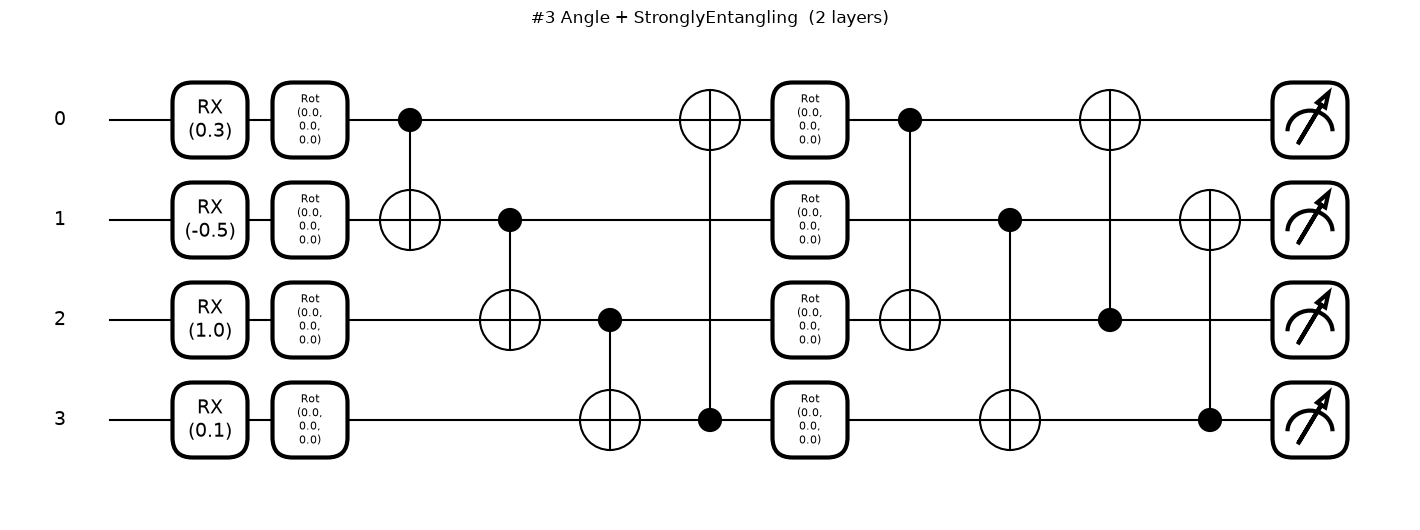

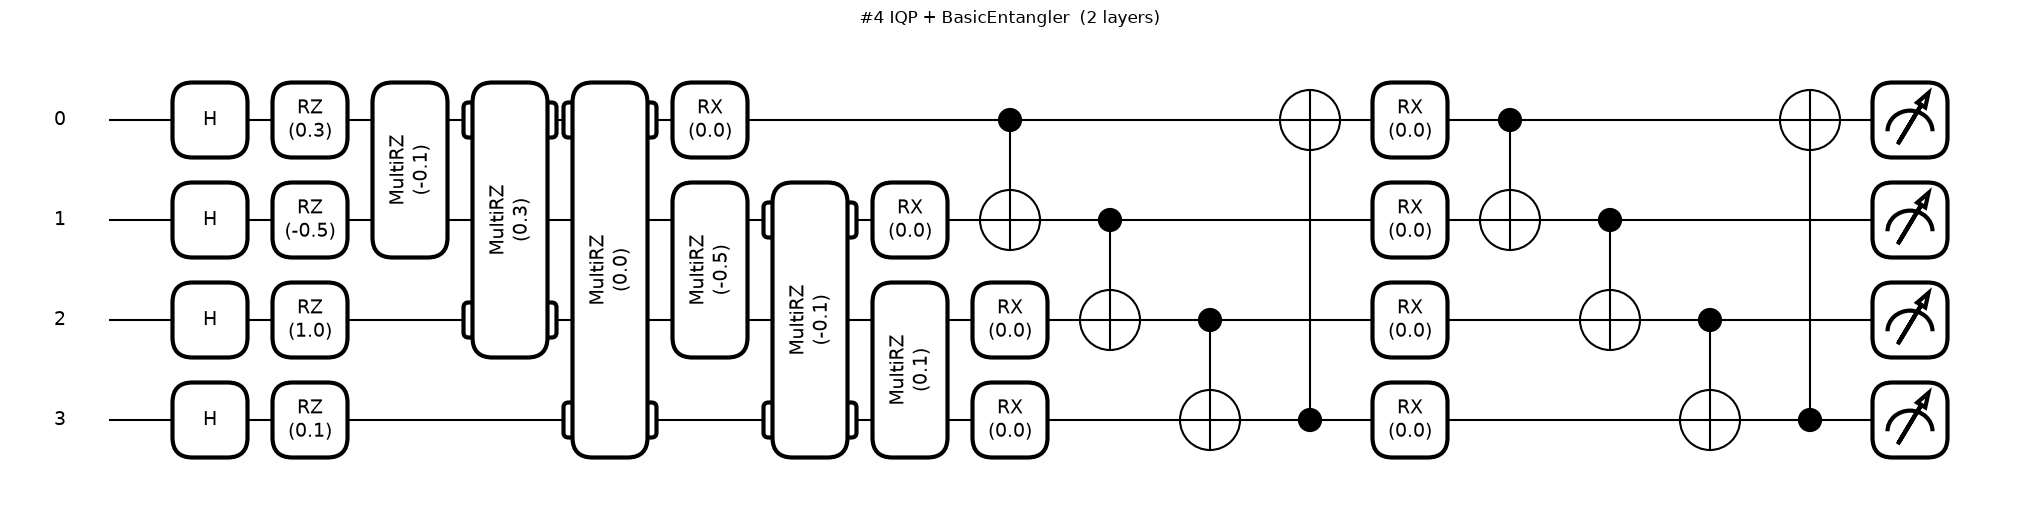

In [7]:
# --- the six quantum layers of the paper: {Angle, IQP} embedding x {BasicEntangler, RandomLayers, StronglyEntangling} template ---
ANSATZ = {1: ("angle", "basic"), 2: ("angle", "random"), 3: ("angle", "strong"),
          4: ("iqp", "basic"),   5: ("iqp", "random"),   6: ("iqp", "strong")}
ANSATZ_NAME = {k: f"#{k} {'Angle' if e == 'angle' else 'IQP'} + {dict(basic='BasicEntangler', random='RandomLayers', strong='StronglyEntangling')[l]}"
               for k, (e, l) in ANSATZ.items()}

def weight_shape(lay):
    return (N_Q_LAYERS, N_QUBITS, 3) if lay == "strong" else (N_Q_LAYERS, N_QUBITS)

def apply_template(x, w, emb, lay):
    """Queue the embedding + trainable template on wires 0..N_QUBITS-1 (works inside a QNode or an annotated queue)."""
    wires = range(N_QUBITS)
    if emb == "angle": qml.AngleEmbedding(x, wires=wires, rotation="X")      # one RX(x_i) per qubit
    else:              qml.IQPEmbedding(x, wires=wires)                        # H, RZ(x_i), RZZ(x_i x_j): Havlicek et al.
    if lay == "basic":    qml.BasicEntanglerLayers(w, wires=wires)             # RX rotations + ring of CNOTs
    elif lay == "random": qml.RandomLayers(w, wires=wires, seed=RANDOM_LAYERS_SEED)   # random rotations + random 2-qubit gates
    else:                 qml.StronglyEntanglingLayers(w, wires=wires)         # Rot(phi, theta, omega) + CNOTs of growing range

def make_pl_layer(k):
    """PennyLane quantum node -> torch layer (the PyTorch twin of the paper's Keras layer), ideal default.qubit simulator."""
    emb, lay = ANSATZ[k]
    dev = qml.device("default.qubit", wires=N_QUBITS)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def qnode(inputs, weights):
        apply_template(inputs, weights, emb, lay)
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]          # N_QUBITS numbers in [-1, 1] go to the next Dense layer
    return qml.qnn.TorchLayer(qnode, {"weights": weight_shape(lay)}, init_method=lambda t: nn.init.uniform_(t, -Q_INIT, Q_INIT))

# a look at the two circuits that matter most (the best hybrid of the paper, #3, and a typical bad one, #4)
x0 = np.array([0.3, -0.5, 1.0, 0.1]); w3 = np.zeros(weight_shape("strong")); w4 = np.zeros(weight_shape("basic"))
for k, w in [(3, w3), (4, w4)]:
    emb, lay = ANSATZ[k]
    dev = qml.device("default.qubit", wires=N_QUBITS)
    @qml.qnode(dev)
    def _c(inputs, weights, emb=emb, lay=lay):
        apply_template(inputs, weights, emb, lay)
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
    fig, ax = qml.draw_mpl(_c, decimals=1, level="device")(x0, w)
    fig.suptitle(ANSATZ_NAME[k] + f"  ({N_Q_LAYERS} layers)", y=1.02); plt.show()

## 5. The hybrid network, the classical counterpart and the training loop

`Net` is the Keras model of the paper's Fig. 1 written in PyTorch: two Dense layers with ReLU, Dropout, the optional quantum layer, and a Dense output
with a sigmoid. With `make_q=None` we get the **classical deep-learning counterpart**; with a quantum layer we get the hybrid. Both are created from the same
seed, so their Dense layers start from identical weights ("the same initial random seed value", which the paper identifies as essential for a fair comparison).

Training is Adam on the binary cross-entropy with shuffled mini-batches. `run_one` trains and tests one model and also handles the random forest and the
SVC baselines, so every model sees exactly the same standardised and clipped data.

In [8]:
class Net(nn.Module):
    """Dense(8,relu) -> Dense(4,relu) -> Dropout -> [quantum layer] -> Dense(1,sigmoid).  qlayer=None gives the classical counterpart."""
    def __init__(self, make_q=None):
        super().__init__()
        self.d1, self.d2 = nn.Linear(N_QUBITS, HIDDEN[0]), nn.Linear(HIDDEN[0], HIDDEN[1])
        self.drop = nn.Dropout(DROPOUT)
        self.out = nn.Linear(N_QUBITS if make_q is not None else HIDDEN[1], 1)
        for m in (self.d1, self.d2, self.out):                  # Keras defaults: Glorot-uniform weights, zero biases
            nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
        self.q = make_q() if make_q is not None else None       # built last, so hybrid and classical start from identical Dense weights
    def forward(self, x):
        h = self.drop(torch.relu(self.d2(torch.relu(self.d1(x)))))
        if self.q is not None: h = self.q(h)
        return self.out(h).squeeze(-1)                          # logit; sigmoid is inside the loss / prediction

def train_model(model, Xtr, ytr, epochs, batch, seed):
    """Adam + binary cross-entropy, shuffled mini-batches (seeded generator). Returns the mean loss of every epoch."""
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    lossf = nn.BCEWithLogitsLoss()
    Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr.astype(np.float32))
    g = torch.Generator().manual_seed(seed)
    hist = []
    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(Xt), generator=g)
        tot = 0.0
        for i in range(0, len(Xt), batch):
            idx = order[i:i + batch]
            opt.zero_grad()
            loss = lossf(model(Xt[idx]), yt[idx])
            loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        hist.append(tot / len(Xt))
    return hist

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return (torch.sigmoid(model(torch.from_numpy(X))).numpy() > 0.5).astype(int)

def metrics(y, p):
    return dict(acc=100 * accuracy_score(y, p), prec=100 * precision_score(y, p, zero_division=0),
                rec=100 * recall_score(y, p, zero_division=0), f1=100 * f1_score(y, p, zero_division=0))

In [9]:
PRED_STORE = {}        # (tag, n, seed, model) -> (y_true, y_pred) for the confusion matrices
LOSS_STORE = {}        # same key -> per-epoch loss

def run_one(kind, n, seed, epochs, batch, make_q=None, tag="main"):
    """Train + test one model ('classical', 'rf', 'svc' or an ansatz id 1..6) on the data sample defined by (n, seed)."""
    Xtr, Xte, ytr, yte = prepare(n, seed)
    seed_everything(seed)                                       # same seed -> same Dense initialisation, same dropout masks, same shuffling
    t0 = time.time()
    if kind == "rf":
        p = RandomForestClassifier(n_estimators=100, random_state=seed).fit(Xtr, ytr).predict(Xte)
    elif kind == "svc":
        p = SVC(kernel="rbf", C=1.0).fit(Xtr, ytr).predict(Xte)
    else:
        model = Net(make_q if kind != "classical" else None)
        hist = train_model(model, Xtr, ytr, epochs, batch, seed)
        p = predict(model, Xte)
        LOSS_STORE[(tag, n, seed, kind)] = hist
    PRED_STORE[(tag, n, seed, kind)] = (yte, p)
    return dict(tag=tag, n=n, seed=seed, model=kind, time=time.time() - t0, **metrics(yte, p))

## 6. Table 1: hybrid vs classical, several runs per sample size

The paper ran each (n, model) combination four times **without** fixing a seed and reports the test accuracy of each run, the maximum, the minimum and the
average. We do the same with seeds 42, 43, ... (one per run, shared by all models so that a run compares like with like), and print the result in the layout of
the paper's Table 1, followed by mean +/- std summaries with F1 and timings and a scatter plot. The random forest and SVC are extra: they show what a
good classical model reaches on these four features.

In [10]:
records = []
t_start = time.time()
for n in SIZES:
    for r in range(N_RUNS):
        seed = SEED + r
        for kind in ["classical", 1, 2, 3, 4, 5, 6, "rf", "svc"]:
            mq = (lambda k=kind: make_pl_layer(k)) if isinstance(kind, int) else None
            records.append(run_one(kind, n, seed, EPOCHS[n], BATCH[n], mq, tag="t1") | dict(run=r))
        row = {x["model"]: x["acc"] for x in records if x["n"] == n and x["run"] == r}
        print(f"n={n:5d} run {r} (seed {seed}) | classical {row['classical']:5.1f} | hybrids " +
              " ".join(f"{row[k]:5.1f}" for k in range(1, 7)) + f" | RF {row['rf']:5.1f} | SVC {row['svc']:5.1f} | elapsed {(time.time()-t_start)/60:5.1f} min")
T1 = pd.DataFrame(records)

n=  100 run 0 (seed 42) | classical  78.9 | hybrids  78.9  84.2  73.7  36.8  78.9  78.9 | RF  84.2 | SVC  84.2 | elapsed   1.3 min


n=  100 run 1 (seed 43) | classical  89.5 | hybrids  84.2  84.2  84.2  89.5  78.9  89.5 | RF  89.5 | SVC  89.5 | elapsed   2.3 min


n=  100 run 2 (seed 44) | classical  94.7 | hybrids  78.9  84.2  84.2  78.9  89.5  78.9 | RF  89.5 | SVC  84.2 | elapsed   3.4 min


n=  100 run 3 (seed 45) | classical  78.9 | hybrids  73.7  63.2  84.2  73.7  68.4  68.4 | RF  89.5 | SVC  94.7 | elapsed   4.5 min


n= 1000 run 0 (seed 42) | classical  92.9 | hybrids  91.9  91.4  91.4  53.3  89.8  91.4 | RF  91.4 | SVC  91.4 | elapsed   7.7 min


...

n= 1000 run 3 (seed 45) | classical  89.8 | hybrids  93.9  93.9  93.9  90.9  95.4  94.4 | RF  97.0 | SVC  94.4 | elapsed  18.2 min


n= 5001 run 0 (seed 42) | classical  92.0 | hybrids  93.1  93.6  93.5  56.2  90.9  93.1 | RF  94.8 | SVC  94.1 | elapsed  22.3 min


n= 5001 run 1 (seed 43) | classical  92.8 | hybrids  93.5  93.0  92.3  89.9  89.7  92.9 | RF  94.2 | SVC  92.8 | elapsed  27.1 min


n= 5001 run 2 (seed 44) | classical  93.7 | hybrids  91.9  92.9  92.8  93.0  92.7  91.1 | RF  95.1 | SVC  93.4 | elapsed  31.4 min


n= 5001 run 3 (seed 45) | classical  92.5 | hybrids  90.5  91.5  90.5  90.1  93.1  92.2 | RF  94.5 | SVC  92.9 | elapsed  35.9 min


In [11]:
COLUMNS = [1, 2, 3, 4, 5, 6, "classical"]
def table1_block(df, n):
    d = df[df.n == n].pivot(index="run", columns="model", values="acc")[COLUMNS]
    d.columns = [f"#{c}" if isinstance(c, int) else "Classical DL" for c in COLUMNS]
    d.index = [f"run {i+1}" for i in d.index]
    d.loc["max"], d.loc["min"], d.loc["avg"] = d.max(), d.min(), d.mean()
    return d.round(1)
for n in SIZES:
    print(f"\n=== n = {n} (our version of the paper's Table 1; test accuracy in %) ===")
    display(table1_block(T1, n))

# all models, mean +- std over the runs: accuracy, F1 (DGA = positive class), wall-clock time (train + predict)
summ = T1.groupby(["n", "model"]).agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), f1_mean=("f1", "mean"),
                                      prec_mean=("prec", "mean"), rec_mean=("rec", "mean"), time_s=("time", "mean")).round(2)
summ = summ.reindex(pd.MultiIndex.from_product([SIZES, ["classical", 1, 2, 3, 4, 5, 6, "rf", "svc"]]), fill_value=np.nan).dropna(how="all")
display(summ)


=== n = 100 (our version of the paper's Table 1; test accuracy in %) ===


,#1,#2,#3,#4,#5,#6,Classical DL
run 1,78.9,84.2,73.7,36.8,78.9,78.9,78.9
run 2,84.2,84.2,84.2,89.5,78.9,89.5,89.5
run 3,78.9,84.2,84.2,78.9,89.5,78.9,94.7
run 4,73.7,63.2,84.2,73.7,68.4,68.4,78.9
max,84.2,84.2,84.2,89.5,89.5,89.5,94.7
min,73.7,63.2,73.7,36.8,68.4,68.4,78.9
avg,78.9,78.9,81.6,69.7,78.9,78.9,85.5



=== n = 1000 (our version of the paper's Table 1; test accuracy in %) ===


,#1,#2,#3,#4,#5,#6,Classical DL
run 1,91.9,91.4,91.4,53.3,89.8,91.4,92.9
run 2,95.4,93.9,95.4,84.3,90.4,94.4,94.9
run 3,93.9,93.4,91.4,93.9,90.4,91.9,92.9
run 4,93.9,93.9,93.9,90.9,95.4,94.4,89.8
max,95.4,93.9,95.4,93.9,95.4,94.4,94.9
min,91.9,91.4,91.4,53.3,89.8,91.4,89.8
avg,93.8,93.1,93.0,80.6,91.5,93.0,92.6



=== n = 5001 (our version of the paper's Table 1; test accuracy in %) ===


,#1,#2,#3,#4,#5,#6,Classical DL
run 1,93.1,93.6,93.5,56.2,90.9,93.1,92.0
run 2,93.5,93.0,92.3,89.9,89.7,92.9,92.8
run 3,91.9,92.9,92.8,93.0,92.7,91.1,93.7
run 4,90.5,91.5,90.5,90.1,93.1,92.2,92.5
max,93.5,93.6,93.5,93.0,93.1,93.1,93.7
min,90.5,91.5,90.5,56.2,89.7,91.1,92.0
avg,92.2,92.7,92.3,82.3,91.6,92.3,92.7


acc_mean  acc_std  f1_mean  prec_mean  rec_mean  time_s
100  classical     85.53     7.89    82.70      87.34     81.85    1.99
     1             78.95     4.30    72.87      79.84     73.91    8.23
     2             78.95    10.53    74.52      75.39     75.50    7.37
     3             81.58     5.26    76.60      86.01     74.70   11.37
     4             69.74    22.89    66.56      80.04     68.35   11.58
     5             78.95     8.59    74.21      79.00     75.60   11.54
     6             78.95     8.59    72.54      82.58     71.13   15.03
     rf            88.16     2.63    85.07      89.72     83.83    0.32
     svc           88.16     5.04    83.88      90.00     83.04    0.01
1000 classical     92.64     2.09    91.88      90.38     93.65    2.56
     1             93.78     1.46    93.13      92.25     94.08   27.87
     2             93.15     1.21    92.46      91.41     93.55   23.50
     3             93.02     2.00    92.15      93.73     90.72   33.95
     4             80.58    18.63    65.72      67.30     64.54   36.39
     5             91.50     2.63    90.75      90.35     91.33   34.85
     6             93.02     1.63    92.33      91.69     93.11   45.05
     rf            94.42     2.52    93.96      93.11     94.86    0.52
     svc           92.39     2.15    91.53      92.54     90.55    0.03
5001 classical     92.74     0.73    92.01      92.53     91.57    3.17
     1             92.23     1.37    91.36      93.07     89.78   39.43
     2             92.74     0.90    92.03      92.74     91.36   39.15
     3             92.26     1.30    91.33      93.98     88.90   54.03
     4             82.31    17.43    67.83      67.19     68.50   38.64
     5             91.60     1.57    90.58      92.57     88.77   38.69
     6             92.31     0.92    91.44      93.09     89.87   50.66
     rf            94.67     0.39    94.15      94.67     93.66    0.91
     svc           93.30     0.60    92.59      93.95     91.27    0.42

### Figures: all runs, training curves

The scatter plot shows the spread that dominates the paper's Table 1: for the same model the accuracy jumps from "constant guess" (about 45-55 %) to "good" (90 %+)
between runs. The loss curves show the reason: some hybrids learn slowly or get stuck, because the quantum layer squashes its input through cosines and
starts with nearly-identity weights.

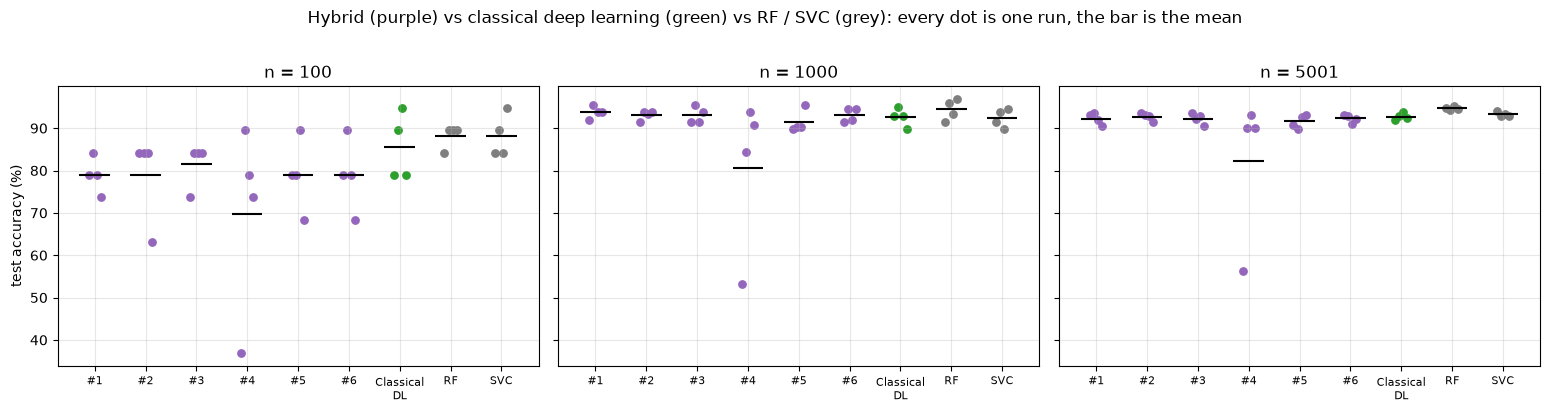

In [12]:
fig, axes = plt.subplots(1, len(SIZES), figsize=(5.2 * len(SIZES), 4), sharey=True, squeeze=False)
labels = ["#1", "#2", "#3", "#4", "#5", "#6", "Classical\nDL", "RF", "SVC"]
for ax, n in zip(axes[0], SIZES):
    d = T1[T1.n == n]
    for j, kind in enumerate([1, 2, 3, 4, 5, 6, "classical", "rf", "svc"]):
        v = d[d.model == kind].acc.values
        ax.scatter(np.full(len(v), j) + np.linspace(-0.12, 0.12, len(v)), v, s=28, color="tab:purple" if isinstance(kind, int) else ("tab:green" if kind == "classical" else "tab:gray"))
        ax.hlines(v.mean(), j - 0.3, j + 0.3, color="k", lw=1.5)
    ax.set_xticks(range(9)); ax.set_xticklabels(labels, fontsize=8); ax.set_title(f"n = {n}"); ax.grid(alpha=0.3)
axes[0][0].set_ylabel("test accuracy (%)")
plt.suptitle("Hybrid (purple) vs classical deep learning (green) vs RF / SVC (grey): every dot is one run, the bar is the mean", y=1.02); plt.tight_layout(); plt.show()

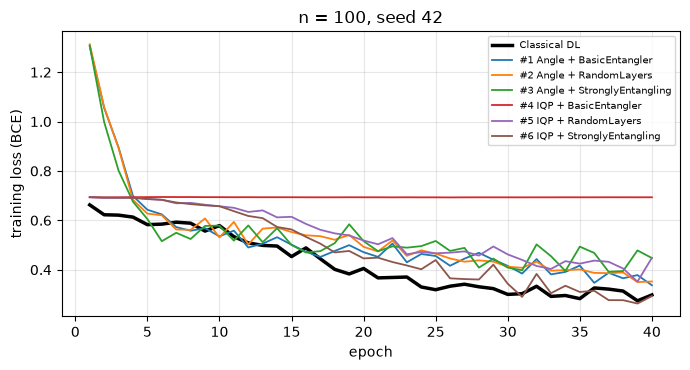

In [13]:
# training curves of the first run at the smallest n: does the quantum layer learn at all?
n0 = SIZES[0]; s0 = SEED
fig, ax = plt.subplots(figsize=(7, 3.8))
for kind in ["classical", 1, 2, 3, 4, 5, 6]:
    h = LOSS_STORE[("t1", n0, s0, kind)]
    ax.plot(range(1, len(h) + 1), h, label="Classical DL" if kind == "classical" else ANSATZ_NAME[kind], lw=2.5 if kind == "classical" else 1.3,
            color="k" if kind == "classical" else None)
ax.set_xlabel("epoch"); ax.set_ylabel("training loss (BCE)"); ax.set_title(f"n = {n0}, seed {s0}"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Table 2: the initial seed

The paper noticed that its accuracies were scattered without a pattern, ran n = 100 with three arbitrary seeds (3, 123, 395) and stated two things: *the same seed
gives the same accuracy* (every seed appears twice in its table), and *different seeds give very different accuracies*. We check both. Our seed fixes the data
sample, the split, the weight initialisation, the dropout masks and the batch order, i.e. everything random.

In [14]:
# Table 2: fixed seeds; the same seed is run twice to see whether the accuracy repeats exactly
rec2 = []
for seed in SEEDS_T2:
    for k in range(1, 7):
        reps = 2 if k in REPEAT_T2 else 1
        for rep in range(reps):
            rec2.append(run_one(k, N_NOISE, seed, EPOCHS_NOISE, BATCH_NOISE, lambda k=k: make_pl_layer(k), tag="t2") | dict(rep=rep))
T2 = pd.DataFrame(rec2)
rows = []
for seed in SEEDS_T2:
    for rep in (0, 1):
        d = T2[(T2.seed == seed) & (T2.rep == rep)]
        if len(d) == 0: continue
        rows.append(pd.Series({f"#{int(r.model)}": r.acc for r in d.itertuples()}, name=f"seed {seed}, run {rep+1}"))
T2_table = pd.DataFrame(rows).round(1)
display(T2_table)
same = []
for seed in SEEDS_T2:
    for k in REPEAT_T2:
        a = T2[(T2.seed == seed) & (T2.model == k)].sort_values("rep").acc.values
        same.append((seed, k, a[0] == a[1], a[0], a[1]))
print("Same seed, same data, same model, run twice -> identical test accuracy in", sum(s[2] for s in same), "of", len(same), "repeated pairs")

,#1,#2,#3,#4,#5,#6
"seed 3, run 1",100.0,94.7,94.7,94.7,94.7,94.7
"seed 3, run 2",100.0,NaN,94.7,94.7,NaN,NaN
"seed 123, run 1",89.5,89.5,89.5,89.5,89.5,89.5
"seed 123, run 2",89.5,NaN,89.5,89.5,NaN,NaN
"seed 395, run 1",73.7,84.2,73.7,89.5,78.9,63.2
"seed 395, run 2",73.7,NaN,73.7,89.5,NaN,NaN


Same seed, same data, same model, run twice -> identical test accuracy in 9 of 9 repeated pairs


## 8. Table 3: noise models of eight IBM devices

On real hardware (and in the paper's `qiskit.aer` simulations) every gate is imperfect. We model the three dominant effects, with numbers read from the calibration
snapshots stored in Qiskit's *fake backends*:

1. **gate errors** (depolarising, from each device's reported one- and two-qubit error rates),
2. **thermal relaxation** during each gate (from T1, T2 and gate durations),
3. **readout error** (a symmetric bit-flip on each measured qubit).

We choose the four physically coupled qubits with the smallest total error as the "chip region" (a noise-aware layout), charge `1 + 3(d-1)` CNOTs for a CNOT
between qubits at chain distance d (SWAP routing), and let a run of neighbouring single-qubit gates cost at most two `sx` pulses (they compile into one
`rz-sx-rz-sx-rz` block). The gate error that thermal relaxation already explains is subtracted before the depolarising part is added (as Qiskit's `NoiseModel.from_backend` does).

**Why our own simulator?** PennyLane's `default.mixed` can do the same, but it needs about a second per training step for these circuits; the grid of 8 devices x 6 circuits x 40 epochs would take
hours. The small density-matrix simulator below is a batched PyTorch re-implementation (about 100 lines) and is **checked in two ways before we use it**:
without noise it must agree with PennyLane's `default.qubit` to machine precision, and with noise it must be close to Qiskit Aer run with the backend's own noise model
(Aer transpiles the circuit with its own gate decomposition, so exact agreement is not expected, only the same magnitude of damping).

In [15]:
# ============ a small differentiable density-matrix simulator with device-calibrated noise ============
# Why not PennyLane's default.mixed? It works, but needs about 1 s per training step for these circuits (hundreds of channel
# insertions) -> hours for the 8 devices x 6 ansatz x 40 epochs grid. This engine does the same maths with batched matrix products.
# It is checked against default.qubit (noise-free) and Qiskit Aer (noisy) in the next cell.
D = 2 ** N_QUBITS
def _cm(m): return torch.tensor(np.array(m, dtype=complex), dtype=torch.complex128)
PX, PY, PZ = _cm([[0, 1], [1, 0]]), _cm([[0, -1j], [1j, 0]]), _cm([[1, 0], [0, -1]])
SIGN = torch.tensor([[1 - 2 * ((b >> (N_QUBITS - 1 - q)) & 1) for q in range(N_QUBITS)] for b in range(D)], dtype=torch.float64)   # <Z_q> from probabilities

def left1(rho, U, w):
    """U acting on wire w from the left on a batch of D x D matrices (wire 0 = most significant bit, PennyLane's convention)."""
    B = rho.shape[0]
    r = rho.reshape(B, 2 ** w, 2, -1)
    out = torch.einsum('ij,bajc->baic', U, r) if U.dim() == 2 else torch.einsum('bij,bajc->baic', U, r)
    return out.reshape(B, D, D)

def conj1(rho, U, w):                                   # U rho U^dagger  (U need not be unitary: used for Kraus operators too)
    t = left1(rho, U, w)
    return left1(t.conj().transpose(-1, -2), U, w)

I2 = _cm(np.eye(2))
def full_op(K, w):                                      # K on wire w, identity elsewhere (D x D)
    return torch.kron(torch.kron(torch.eye(2 ** w, dtype=torch.complex128), K), torch.eye(2 ** (N_QUBITS - w - 1), dtype=torch.complex128))

def superop(Ks):                                        # Kraus operators (D x D) -> D^2 x D^2 matrix acting on the row-major vec(rho)
    return sum(torch.kron(K, K.conj()) for K in Ks)

def depol_sup(lam, wires):                              # (1-lam) rho + lam * (rho with the given wires completely depolarised)
    full = torch.eye(D * D, dtype=torch.complex128)
    for w in wires:                                     # complete depolarisation of one wire = average over I, X, Y, Z
        full = superop([full_op(P, w) / 2 for P in (I2, PX, PY, PZ)]) @ full
    return (1 - lam) * torch.eye(D * D, dtype=torch.complex128) + lam * full

def thermal_sup(t, t1, t2, w):
    """Thermal relaxation during a gate of duration t: amplitude damping (T1) followed by the extra pure dephasing implied by T2."""
    t2 = min(t2, 2 * t1)
    g = 1 - np.exp(-t / t1)                                          # amplitude-damping probability
    lam = 1 - np.exp(-2 * t * (1 / t2 - 1 / (2 * t1)))               # extra dephasing so that coherences decay as exp(-t/T2)
    ad = superop([full_op(_cm([[1, 0], [0, np.sqrt(1 - g)]]), w), full_op(_cm([[0, np.sqrt(g)], [0, 0]]), w)])
    ph = superop([full_op(_cm([[1, 0], [0, np.sqrt(1 - lam)]]), w), full_op(_cm([[0, 0], [0, np.sqrt(lam)]]), w)])
    return ph @ ad

def relax_infidelity(t, t1, t2):                        # average gate infidelity caused by T1/T2 during time t (one qubit)
    t2 = min(t2, 2 * t1)
    return (3 - np.exp(-t / t1) - 2 * np.exp(-t / t2)) / 6

_SUP = {}
def gate_superop(noise, kind, wires, k):
    """Noise channel that follows a gate (depolarising part + thermal relaxation) as ONE cached D^2 x D^2 matrix."""
    key = (id(noise), kind, tuple(wires), k)
    if key not in _SUP:
        if kind == "1q":
            q = wires[0]; t = k * noise["t_sx"]; e = 1 - (1 - noise["sx_err"][q]) ** k
            e_dep = max(e - relax_infidelity(t, noise["t1"][q], noise["t2"][q]), 0.0)    # reported gate error minus the part T1/T2 already explain
            S = thermal_sup(t, noise["t1"][q], noise["t2"][q], q) @ depol_sup(min(2 * e_dep, 1.0), [q])
        else:
            a, b = wires; e, t = noise["cx_err"][a][b], noise["cx_time"][a][b]
            e_dep = max(e - relax_infidelity(t, noise["t1"][a], noise["t2"][a]) - relax_infidelity(t, noise["t1"][b], noise["t2"][b]), 0.0)
            S = (thermal_sup(t, noise["t1"][b], noise["t2"][b], b) @ thermal_sup(t, noise["t1"][a], noise["t2"][a], a)
                 @ depol_sup(min(4 * e_dep / 3, 1.0), [a, b]))
        _SUP[key] = S
    return _SUP[key]

def apply_sup(rho, S):
    return (rho.reshape(rho.shape[0], D * D) @ S.T).reshape(-1, D, D)

_PERM = {}
def cnot(rho, c, t):
    key = (c, t)
    if key not in _PERM:
        idx = np.arange(D); _PERM[key] = torch.tensor(idx ^ (((idx >> (N_QUBITS - 1 - c)) & 1) << (N_QUBITS - 1 - t)), dtype=torch.long)
    p = _PERM[key]
    return rho[:, p][:, :, p]

BASIS = {"RX", "RY", "RZ", "Rot", "Hadamard", "CNOT"}
N_PULSES = {"Hadamard": 1, "RX": 2, "RY": 2, "Rot": 2, "RZ": 0}      # CHOICE: number of sx pulses a gate costs on IBM hardware (RZ is virtual)

def flatten(op):
    """Decompose an operator recursively until only gates of BASIS remain."""
    if op.name in BASIS: return [op]
    out = []
    for d in op.decomposition(): out += flatten(d)
    return out

def circuit_ops(x, w, emb, lay):
    with qml.queuing.AnnotatedQueue() as q:
        apply_template(x, w, emb, lay)
    ops = []
    for o in q.queue: ops += flatten(o)
    return ops

def noisy_expz(x, w, emb, lay, noise=None):
    """<Z_q> of all qubits for a batch x (B x N_QUBITS), density-matrix simulation; noise=None -> ideal."""
    B = x.shape[0]
    rho = torch.zeros(B, D, D, dtype=torch.complex128); rho[:, 0, 0] = 1
    pending = [0] * N_QUBITS          # sx pulses waiting on each wire: neighbouring single-qubit gates compile into ONE rz-sx-rz-sx-rz block (<= 2 pulses)
    def flush(rho, q):
        if noise is not None and pending[q] > 0: rho = apply_sup(rho, gate_superop(noise, "1q", [q], pending[q]))
        pending[q] = 0
        return rho
    for o in circuit_ops(x, w, emb, lay):
        ws = [int(i) for i in o.wires]
        if o.name == "CNOT":
            for q in ws: rho = flush(rho, q)
            rho = cnot(rho, *ws)
            if noise is not None: rho = apply_sup(rho, gate_superop(noise, "2q", ws, None))
        else:
            U = o.matrix(); U = (U if torch.is_tensor(U) else torch.as_tensor(U)).to(torch.complex128)
            rho = conj1(rho, U, ws[0])
            pending[ws[0]] = min(2, pending[ws[0]] + N_PULSES[o.name])
    for q in range(N_QUBITS): rho = flush(rho, q)
    ez = torch.einsum('bd,dq->bq', torch.diagonal(rho, dim1=1, dim2=2).real, SIGN)
    if noise is not None: ez = ez * (1 - 2 * torch.tensor(noise["ro"], dtype=torch.float64))   # symmetric readout error flips <Z> by (1-2r)
    return ez

class EngineLayer(nn.Module):
    def __init__(self, k, noise=None):
        super().__init__()
        self.emb, self.lay, self.noise = *ANSATZ[k], noise
        w = torch.empty(*weight_shape(self.lay)); nn.init.uniform_(w, -Q_INIT, Q_INIT)    # same RNG draws as make_pl_layer
        self.weights = nn.Parameter(w)
    def forward(self, x):
        return noisy_expz(x.double(), self.weights.double(), self.emb, self.lay, self.noise).float()

In [16]:
# --- noise parameters read from the fake IBM backends (calibration snapshots shipped with qiskit-ibm-runtime) ---
DEVICES = [  # paper's name, fake backend that stands in for it
    ("ibmq_16_melbourne", "FakeMelbourneV2"), ("ibmq_5_yorktown", "FakeYorktownV2"), ("ibmq_athens", "FakeAthensV2"), ("ibmq_belem", "FakeBelemV2"),
    ("ibmq_lima", "FakeLimaV2"), ("ibmq_quito", "FakeQuitoV2"), ("ibmq_santiago", "FakeSantiagoV2"),
    ("ibmqx2", "FakeEssexV2")]      # CHOICE: ibmqx2 is the old name of the Yorktown chip, which is already in the list; Essex is a sister 5-qubit device
if N_DEVICES < len(DEVICES):       # FAST_MODE: a noisy, a medium and a quiet device
    DEVICES = [d for d in DEVICES if d[0] in ("ibmq_16_melbourne", "ibmq_athens", "ibmq_lima")][:N_DEVICES]

def best_chain(backend, k=N_QUBITS):
    """The path of k coupled physical qubits with the smallest summed CNOT + readout error (what a noise-aware layout would pick)."""
    t = backend.target
    edges = {tuple(q): p.error for q, p in t["cx"].items()}
    ro = {q[0]: p.error for q, p in t["measure"].items()}
    adj = {}
    for (a, b) in edges: adj.setdefault(a, set()).add(b)
    best, best_cost = None, 1e9
    def dfs(path):
        nonlocal best, best_cost
        if len(path) == k:
            cost = sum(min(edges.get((path[i], path[i + 1]), 1), edges.get((path[i + 1], path[i]), 1)) for i in range(k - 1)) + sum(ro[q] for q in path)
            if cost < best_cost: best, best_cost = list(path), cost
            return
        for nb in adj.get(path[-1], ()):
            if nb not in path: dfs(path + [nb])
    for s in adj: dfs([s])
    return best

def device_noise(backend, k=N_QUBITS):
    """Gate errors, durations, T1/T2 and readout errors of the chosen 4-qubit chain, in the dictionary format of noisy_expz."""
    t = backend.target
    chain = best_chain(backend, k)
    one = "sx" if "sx" in t.operation_names else "u2"                    # one-pulse gate of the device's basis
    edges = {tuple(q): p for q, p in t["cx"].items()}
    e_edge = [np.mean([edges[(chain[i], chain[i + 1])].error if (chain[i], chain[i + 1]) in edges else edges[(chain[i + 1], chain[i])].error]) for i in range(k - 1)]
    d_edge = [(edges[(chain[i], chain[i + 1])] if (chain[i], chain[i + 1]) in edges else edges[(chain[i + 1], chain[i])]).duration for i in range(k - 1)]
    e_cx, t_cx = float(np.mean(e_edge)), float(np.mean(d_edge))
    cx_err, cx_time = np.zeros((k, k)), np.zeros((k, k))
    for a in range(k):
        for b in range(k):
            if a != b:
                hops = 1 + 3 * (abs(a - b) - 1)          # CHOICE: a CNOT over distance d costs 1 + 3(d-1) CNOTs after SWAP routing on a chain
                cx_err[a, b] = 1 - (1 - e_cx) ** hops; cx_time[a, b] = hops * t_cx
    return dict(chain=chain, sx_err=[t[one][(q,)].error for q in chain], t_sx=float(np.mean([t[one][(q,)].duration for q in chain])),
                t1=[backend.qubit_properties(q).t1 for q in chain], t2=[backend.qubit_properties(q).t2 for q in chain],
                ro=[t["measure"][(q,)].error for q in chain], cx_err=cx_err.tolist(), cx_time=cx_time.tolist(), e_cx=e_cx)

BACKENDS, NOISE = {}, {}
for paper_name, cls in DEVICES:
    BACKENDS[paper_name] = getattr(fake_provider, cls)()
    NOISE[paper_name] = device_noise(BACKENDS[paper_name])
summary = pd.DataFrame({name: dict(backend=cls, chain=str(NOISE[name]["chain"]), sx_error=np.mean(NOISE[name]["sx_err"]), cx_error=NOISE[name]["e_cx"],
                                   readout_error=np.mean(NOISE[name]["ro"]), T1_us=np.mean(NOISE[name]["t1"]) * 1e6, T2_us=np.mean(NOISE[name]["t2"]) * 1e6)
                        for (name, cls) in DEVICES}).T
display(summary.round(5))

,backend,chain,sx_error,cx_error,readout_error,T1_us,T2_us
ibmq_16_melbourne,FakeMelbourneV2,"[0, 1, 2, 3]",0.000788,0.020747,0.040975,58.174627,57.600946
ibmq_5_yorktown,FakeYorktownV2,"[1, 0, 2, 3]",0.000985,0.020194,0.059325,52.726214,36.730092
ibmq_athens,FakeAthensV2,"[0, 1, 2, 3]",0.000527,0.01483,0.01535,54.752594,79.856006
ibmq_belem,FakeBelemV2,"[2, 1, 3, 4]",0.000428,0.013129,0.02765,77.886948,72.635349
ibmq_lima,FakeLimaV2,"[2, 1, 3, 4]",0.000396,0.012066,0.0364,61.991342,68.300722
ibmq_quito,FakeQuitoV2,"[0, 1, 3, 4]",0.001663,0.033149,0.035575,69.368148,61.129502
ibmq_santiago,FakeSantiagoV2,"[1, 2, 3, 4]",0.000196,0.005936,0.0144,136.367204,101.7305
ibmqx2,FakeEssexV2,"[0, 1, 3, 4]",0.000551,0.018962,0.034475,90.736465,130.634857


In [17]:
# --- check 1: the engine without noise must equal PennyLane's default.qubit; check 2: with noise it must be close to Qiskit Aer ---
g = np.random.default_rng(SEED)
rows = []
for k in range(1, 7):
    emb, lay = ANSATZ[k]
    W = torch.tensor(g.uniform(0, 2 * np.pi, weight_shape(lay)), dtype=torch.float64)
    X = torch.tensor(g.uniform(0, 3, (5, N_QUBITS)), dtype=torch.float64)
    dev = qml.device("default.qubit", wires=N_QUBITS)
    @qml.qnode(dev, interface="torch")
    def ref(inputs, weights, emb=emb, lay=lay):
        apply_template(inputs, weights, emb, lay)
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
    a = torch.stack(ref(X, W), dim=-1)
    b = noisy_expz(X, W, emb, lay, None)
    rows.append(dict(ansatz=ANSATZ_NAME[k], max_abs_diff_vs_default_qubit=float((a - b).abs().max())))
display(pd.DataFrame(rows))

def to_qiskit(ops):
    qc = QuantumCircuit(N_QUBITS, N_QUBITS)
    for o in ops:
        w = int(o.wires[0]); p = [float(v) for v in o.parameters]
        if o.name == "CNOT": qc.cx(int(o.wires[0]), int(o.wires[1]))
        elif o.name == "Hadamard": qc.h(w)
        elif o.name == "RX": qc.rx(p[0], w)
        elif o.name == "RY": qc.ry(p[0], w)
        elif o.name == "RZ": qc.rz(p[0], w)
        elif o.name == "Rot": qc.rz(p[0], w); qc.ry(p[1], w); qc.rz(p[2], w)       # Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
    qc.measure(range(N_QUBITS), range(N_QUBITS))
    return qc

def aer_expz(x, w, emb, lay, backend, chain, shots=20000):
    """<Z_q> from Qiskit Aer with the backend's own noise model, circuit transpiled onto the same 4-qubit chain."""
    qc = to_qiskit(circuit_ops(torch.tensor(x), torch.tensor(w), emb, lay))
    sim = AerSimulator.from_backend(backend, seed_simulator=SEED)
    tqc = transpile(qc, sim, initial_layout=chain, optimization_level=1, seed_transpiler=SEED)
    counts = sim.run(tqc, shots=shots).result().get_counts()
    z = np.zeros(N_QUBITS)
    for key, c in counts.items():
        for q in range(N_QUBITS): z[q] += c * (1 - 2 * int(key[::-1][q]))
    return z / shots

rows = []
for name in list(NOISE)[:2]:
    for k in (3, 4):
        emb, lay = ANSATZ[k]
        W = g.uniform(0, 2 * np.pi, weight_shape(lay)); X = g.uniform(0, 3, (3, N_QUBITS))
        eng = noisy_expz(torch.tensor(X), torch.tensor(W), emb, lay, NOISE[name]).numpy()
        ideal = noisy_expz(torch.tensor(X), torch.tensor(W), emb, lay, None).numpy()
        aer = np.array([aer_expz(x, W, emb, lay, BACKENDS[name], NOISE[name]["chain"]) for x in X])
        rows.append(dict(device=name, ansatz=ANSATZ_NAME[k], ideal_vs_engine=np.abs(ideal - eng).mean(), ideal_vs_aer=np.abs(ideal - aer).mean(),
                         engine_vs_aer=np.abs(eng - aer).mean(), max_engine_vs_aer=np.abs(eng - aer).max()))
display(pd.DataFrame(rows).round(4))
print("Columns: mean |difference| of <Z> over qubits and 3 inputs (max in the last column); Aer's own shot noise is about 0.007.")
print("The engine follows Aer to within a few hundredths. It is somewhat MORE pessimistic than Aer on the noisiest device because it charges 3 CNOTs for")
print("every SWAP and never re-uses a routing permutation (e.g. 26 vs 17 two-qubit gates for circuit #3), and uses symmetric readout errors.")

,ansatz,max_abs_diff_vs_default_qubit
0,#1 Angle + BasicEntangler,3.330669e-16
1,#2 Angle + RandomLayers,2.775558e-16
2,#3 Angle + StronglyEntangling,6.661338e-16
3,#4 IQP + BasicEntangler,1.665335e-16
4,#5 IQP + RandomLayers,3.885781e-16
5,#6 IQP + StronglyEntangling,4.163336e-16


,device,ansatz,ideal_vs_engine,ideal_vs_aer,engine_vs_aer,max_engine_vs_aer
0,ibmq_16_melbourne,#3 Angle + StronglyEntangling,0.0618,0.0276,0.0344,0.0664
1,ibmq_16_melbourne,#4 IQP + BasicEntangler,0.1058,0.0882,0.0390,0.0662
2,ibmq_5_yorktown,#3 Angle + StronglyEntangling,0.0584,0.0350,0.0406,0.0807
3,ibmq_5_yorktown,#4 IQP + BasicEntangler,0.1342,0.1005,0.0460,0.0902


Columns: mean |difference| of <Z> over qubits and 3 inputs (max in the last column); Aer's own shot noise is about 0.007.
The engine follows Aer to within a few hundredths. It is somewhat MORE pessimistic than Aer on the noisiest device because it charges 3 CNOTs for
every SWAP and never re-uses a routing permutation (e.g. 26 vs 17 two-qubit gates for circuit #3), and uses symmetric readout errors.


### Training and testing under noise

Like the paper, the hybrid models are *trained and tested* with the noisy circuit (n = 100, seed 123). The first row is the noise-free control run through the same
engine; it should reproduce the seed-123 row of Table 2 from PennyLane, which is a good end-to-end check of the engine.

In [18]:
# Table 3: n = 100, seed 123, the six hybrids trained and tested under the noise model of each device.
rec3 = []
t_start = time.time()
for name in ["0 (without noise)"] + [d[0] for d in DEVICES]:
    for k in range(1, 7):
        nz = None if name.startswith("0") else NOISE[name]
        rec3.append(run_one(k, N_NOISE, SEED_NOISE, EPOCHS_NOISE, BATCH_NOISE, lambda k=k, nz=nz: EngineLayer(k, nz), tag="t3:" + name) | dict(device=name))
    print(f"{name:20s}", " ".join(f"{x['acc']:5.1f}" for x in rec3[-6:]), f"| elapsed {(time.time()-t_start)/60:4.1f} min")
T3 = pd.DataFrame(rec3)
T3_table = T3.pivot(index="device", columns="model", values="acc")[list(range(1, 7))]
T3_table = T3_table.reindex(["0 (without noise)"] + [d[0] for d in DEVICES])
T3_table.columns = [f"#{c}" for c in T3_table.columns]
noisy_rows = T3_table.iloc[1:]
T3_table.loc["maximum"], T3_table.loc["minimum"], T3_table.loc["average"] = noisy_rows.max(), noisy_rows.min(), noisy_rows.mean()
display(T3_table.round(1))

pl123 = T2[(T2.seed == 123) & (T2.rep == 0)].sort_values("model").acc.values if 123 in SEEDS_T2 else None
if pl123 is not None:
    print("noise-free row from the PennyLane default.qubit runs of Table 2 (seed 123):", np.round(pl123, 1), "\nnoise-free row from the density-matrix engine:                        ", T3_table.iloc[0].values.round(1))

0 (without noise)     89.5  89.5  89.5  89.5  84.2  89.5 | elapsed  3.3 min


ibmq_16_melbourne     89.5  89.5  89.5  78.9  89.5  84.2 | elapsed  8.3 min


ibmq_5_yorktown       89.5  89.5  89.5  78.9  89.5  84.2 | elapsed 11.7 min


ibmq_athens           89.5  89.5  89.5  78.9  84.2  84.2 | elapsed 14.2 min


ibmq_belem            89.5  89.5  89.5  84.2  89.5  84.2 | elapsed 17.1 min


...

ibmq_quito            89.5  89.5  89.5  63.2  89.5  89.5 | elapsed 21.0 min


ibmq_santiago         89.5  89.5  89.5  84.2  89.5  84.2 | elapsed 23.3 min


ibmqx2                89.5  89.5  89.5  84.2  84.2  84.2 | elapsed 25.1 min


,#1,#2,#3,#4,#5,#6
device,,,,,,
0 (without noise),89.5,89.5,89.5,89.5,84.2,89.5
ibmq_16_melbourne,89.5,89.5,89.5,78.9,89.5,84.2
ibmq_5_yorktown,89.5,89.5,89.5,78.9,89.5,84.2
ibmq_athens,89.5,89.5,89.5,78.9,84.2,84.2
ibmq_belem,89.5,89.5,89.5,84.2,89.5,84.2
ibmq_lima,89.5,89.5,89.5,84.2,89.5,84.2
ibmq_quito,89.5,89.5,89.5,63.2,89.5,89.5
ibmq_santiago,89.5,89.5,89.5,84.2,89.5,84.2
ibmqx2,89.5,89.5,89.5,84.2,84.2,84.2


noise-free row from the PennyLane default.qubit runs of Table 2 (seed 123): [89.5 89.5 89.5 89.5 89.5 89.5] 
noise-free row from the density-matrix engine:                         [89.5 89.5 89.5 89.5 84.2 89.5]


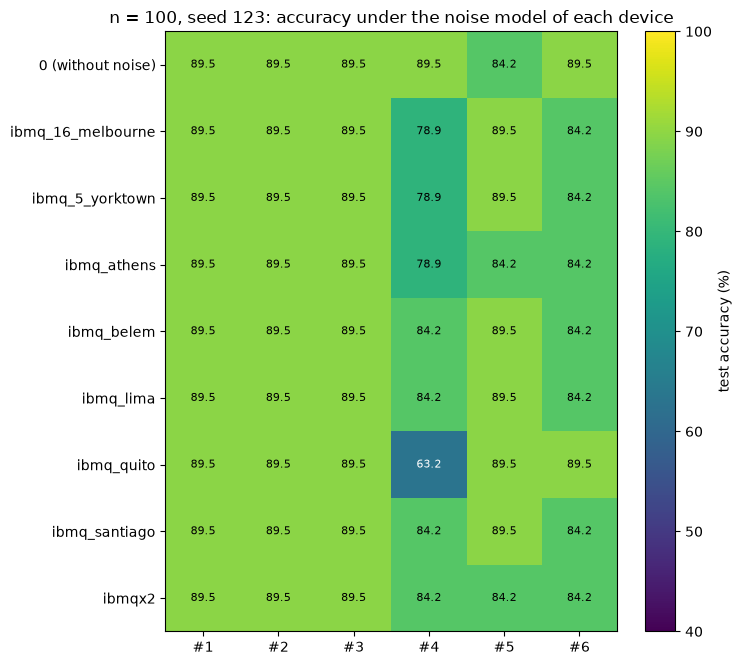

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 0.55 * len(T3_table.iloc[:-3]) + 1.8))
data = T3_table.iloc[:-3].astype(float)
im = ax.imshow(data.values, vmin=40, vmax=100, cmap="viridis", aspect="auto")
ax.set_xticks(range(6)); ax.set_xticklabels(data.columns); ax.set_yticks(range(len(data))); ax.set_yticklabels(data.index)
for i in range(data.shape[0]):
    for j in range(6):
        ax.text(j, i, f"{data.values[i, j]:.1f}", ha="center", va="center", color="w" if data.values[i, j] < 75 else "k", fontsize=8)
plt.colorbar(im, label="test accuracy (%)"); ax.set_title(f"n = {N_NOISE}, seed {SEED_NOISE}: accuracy under the noise model of each device"); plt.tight_layout(); plt.show()

### (Optional) a real device

The paper only simulates the devices, and so do we. The next cell shows how a circuit would be sent to a real backend; it needs an IBM Quantum token in
`IBM_TOKEN` and is **skipped by default (and untested here)**.

In [20]:
# Optional, UNTESTED here (needs an IBM Quantum account): evaluate the trained-free circuit #3 with random weights on a real backend and
# compare <Z> with the ideal simulation. Skipped unless IBM_TOKEN is set in the configuration cell.
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=N_QUBITS)
    emb, lay = ANSATZ[3]
    W = np.random.default_rng(SEED).uniform(0, 2 * np.pi, weight_shape(lay)); x = np.array([0.3, 1.2, 0.7, 2.0])
    qc = to_qiskit(circuit_ops(torch.tensor(x), torch.tensor(W), emb, lay))
    tqc = transpile(qc, backend, optimization_level=1, seed_transpiler=SEED)
    res = SamplerV2(mode=backend).run([tqc], shots=4000).result()[0].data.c.get_counts()
    z = np.zeros(N_QUBITS)
    for key, c in res.items():
        for q in range(N_QUBITS): z[q] += c * (1 - 2 * int(key[::-1][q])) / 4000
    print("backend", backend.name, "\nhardware <Z>:", z.round(3), "\nideal    <Z>:", noisy_expz(torch.tensor(x[None]), torch.tensor(W), emb, lay, None).numpy().round(3))
else:
    print("IBM_TOKEN is empty: hardware cell skipped (the paper's own results are noise-model simulations as well).")

IBM_TOKEN is empty: hardware cell skipped (the paper's own results are noise-model simulations as well).


## 9. Confusion matrices, precision / recall / F1 and timings

Accuracy hides which kind of error a model makes. With DGA as the positive class, a missed DGA domain (false negative) is the expensive error for security:
the bot gets through. The matrices below are for the first run at the largest n.

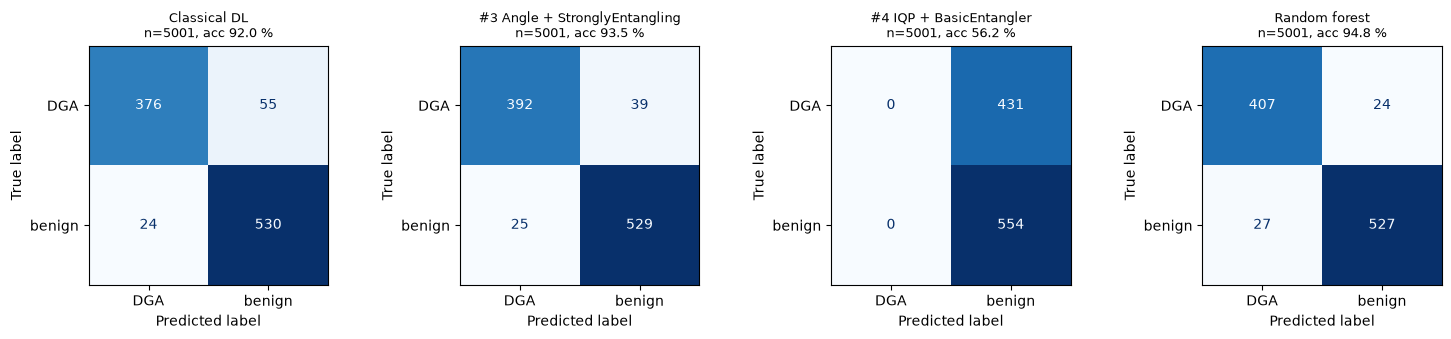

,acc,prec,rec,f1,time
Classical DL,91.98,94.00,87.24,90.49,3.05
#1 Angle + BasicEntangler,93.10,93.11,90.95,92.02,35.68
#2 Angle + RandomLayers,93.60,93.81,91.42,92.60,33.92
#3 Angle + StronglyEntangling,93.50,94.00,90.95,92.45,50.90
#4 IQP + BasicEntangler,56.24,0.00,0.00,0.00,38.35
#5 IQP + RandomLayers,90.86,93.38,85.15,89.08,38.93
#6 IQP + StronglyEntangling,93.10,94.59,89.33,91.89,46.23
rf,94.82,93.78,94.43,94.10,0.84
svc,94.11,94.09,92.34,93.21,0.39


In [21]:
# Confusion matrices (DGA = positive class) of the first run at the largest n, plus precision / recall / F1 of that run
n_big = SIZES[-1]; s_big = SEED
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (kind, title) in zip(axes, [("classical", "Classical DL"), (3, ANSATZ_NAME[3]), (4, ANSATZ_NAME[4]), ("rf", "Random forest")]):
    y, p = PRED_STORE[("t1", n_big, s_big, kind)]
    ConfusionMatrixDisplay(confusion_matrix(y, p, labels=[1, 0]), display_labels=["DGA", "benign"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{title}\nn={n_big}, acc {100*(y==p).mean():.1f} %", fontsize=9)
plt.tight_layout(); plt.show()
one = T1[(T1.n == n_big) & (T1.run == 0)].set_index("model")[["acc", "prec", "rec", "f1", "time"]].round(2)
one.index = [("Classical DL" if m == "classical" else (ANSATZ_NAME[m] if isinstance(m, int) else m)) for m in one.index]
display(one)

## 10. Side by side with the paper

Every number of the paper that this experiment can test is compared below. Verdicts: **reproduced** if we are within 2 accuracy points, otherwise **not reached** (ours lower)
or **exceeded** (ours higher); **cannot be checked** where the experiment is not available (n = 10,000, real hardware). Note that at n = 100 the paper's own
resolution is 5.3 points per test sample and its entries are single unseeded runs, so a "reproduced" on an individual cell is partly luck and a "not reached" is often just noise.

In [22]:
# ======================= paper's numbers (typed in from Tables 1-3 and the text) =======================
PAPER_T1 = {  # n: (rows of runs: [#1..#6, classical], hybrid-average row, max row)
    100:   dict(runs=[[42.1, 68.4, 52.6, 94.7, 57.8, 52.6, 89.4], [47.3, 42.1, 42.1, 63.1, 42.1, 42.1, 84.2], [89.4, 89.4, 89.4, 89.4, 89.4, 78.9, 94.7], [78.9, 78.9, 89.4, 42.1, 42.1, 78.9, 73.6]],
                avg=[64.4, 69.7, 68.4, 72.3, 57.9, 63.1, 85.5]),
    1000:  dict(runs=[[93.4, 93.9, 72.8, 48.2, 92.4, 89.9, 93.9], [52.7, 89.4, 71.3, 48.2, 88.4, 80.4, 93.9], [81.4, 81.4, 85.4, 84.9, 54.2, 79.8, 93.9], [93.4, 92.9, 88.9, 93.4, 93.4, 93.4, 93.4]],
                avg=[80.2, 89.4, 79.6, 68.7, 82.1, 85.9, 93.8]),
    10000: dict(runs=[[88.7, 88.7, 64.5, 89.5, 89.3, 82.6, 89.6], [89.4, 88.3, 88.7, 44.5, 60.5, 83.1, 89.3], [87.5, 79.4, 84.3, 89.6, 89.4, 84.0, 89.4], [88.6, 77.4, 89.4, 89.5, 89.3, 89.7, 89.5]],
                avg=[88.6, 83.5, 81.7, 78.3, 82.1, 84.9, 89.5]),
}
PAPER_T2 = {3: [42.1, 52.6, 42.1, 52.6, 47.3, 47.3], 123: [89.4, 89.4, 89.4, 89.4, 89.4, 78.9], 395: [89.4, 89.4, 42.1, 73.6, 52.6, 42.1]}
PAPER_T3_AVG = [82.9, 89.4, 91.4, 77.6, 75.0, 86.8]
PAPER_T3_MAX = [89.4, 89.4, 94.7, 94.7, 89.4, 89.4]
TOL = 2.0     # accuracy points

def verdict(ours, paper, tol=TOL):
    if abs(ours - paper) <= tol: return "reproduced"
    return "exceeded (+%.1f)" % (ours - paper) if ours > paper else "not reached (%.1f)" % (ours - paper)

paper_n_for = {100: 100, 1000: 1000, 5001: 10000}        # our largest sample (5,001 rows) stands in for the paper's n = 10,000
claims = []
for n in SIZES:
    pn = paper_n_for[n]; d = T1[T1.n == n]
    note = "" if n == pn else f" [substitute: n={n} instead of {pn}]"
    hyb_best = d[d.model.isin(range(1, 7))].acc.max()
    claims.append((f"hybrid maximum accuracy, n={pn}{note}", max(max(r[:6]) for r in PAPER_T1[pn]["runs"]), hyb_best, n == pn))
    claims.append((f"classical DL average accuracy, n={pn}{note}", PAPER_T1[pn]["avg"][6], d[d.model == "classical"].acc.mean(), n == pn))
    for j in range(6):
        claims.append((f"hybrid {ANSATZ_NAME[j+1]} average, n={pn}{note}", PAPER_T1[pn]["avg"][j], d[d.model == j + 1].acc.mean(), n == pn))
rows = []
for text, p, o, exact in claims:
    v = verdict(o, p) if exact else "cannot be checked at the paper's n (" + verdict(o, p) + " at the substitute n)"
    rows.append(dict(claim=text, paper=p, notebook=round(o, 1), verdict=v))

# qualitative claims
for n in SIZES:
    pn = paper_n_for[n]; d = T1[T1.n == n]
    h = np.mean([d[d.model == k].acc.mean() for k in range(1, 7)]); c = d[d.model == "classical"].acc.mean()
    rows.append(dict(claim=f"hybrid average over all six ansatz is below the classical average, n={pn}" + ("" if n == pn else " [substitute n]"),
                     paper=f"{np.mean(PAPER_T1[pn]['avg'][:6]):.1f} < {PAPER_T1[pn]['avg'][6]:.1f}", notebook=f"{h:.1f} vs {c:.1f}",
                     verdict=("reproduced" if h < c else "not reached (hybrid not below classical)") + ("" if n == pn else " (substitute n)")))
# Table 2: determinism and seed influence
det = [s[2] for s in same]
rows.append(dict(claim="same initial seed -> identical accuracy (Table 2, run twice)", paper="identical in all pairs", notebook=f"identical in {sum(det)}/{len(det)} pairs",
                 verdict="reproduced" if all(det) else "not reached"))
spread = [np.ptp([T2[(T2.seed == s) & (T2.model == k) & (T2.rep == 0)].acc.iloc[0] for s in SEEDS_T2]) for k in range(1, 7)]
rows.append(dict(claim="the seed changes the accuracy of the hybrid model (Table 2: spread across seeds)", paper="up to 47.3 points (#3: 42.1 -> 89.4)", notebook=f"largest spread {max(spread):.1f} points",
                 verdict="reproduced" if max(spread) >= 5 else "not reached (seed barely matters here)"))
cells = [(s, k) for s in SEEDS_T2 for k in range(1, 7)]
hit = sum(abs(T2[(T2.seed == s) & (T2.model == k) & (T2.rep == 0)].acc.iloc[0] - PAPER_T2[s][k - 1]) <= TOL for s, k in cells)
rows.append(dict(claim="individual Table-2 cells (seed x ansatz) within 2 points", paper=f"{len(cells)} cells", notebook=f"{hit}/{len(cells)} within 2 points",
                 verdict="reproduced" if hit == len(cells) else ("partly" if hit > len(cells) / 2 else "not reached (cell values are not seed-transferable across implementations)")))
# Table 3: noise
avg3 = T3_table.loc["average"].values.astype(float); max3 = T3_table.loc["maximum"].values.astype(float)
best = int(np.argmax(avg3)) + 1
rows.append(dict(claim="under device noise, #3 (Angle + StronglyEntangling) has the best average of the six ansatz", paper="#3 (91.4)", notebook=f"best is #{best} ({avg3[best-1]:.1f}); #3 = {avg3[2]:.1f}",
                 verdict="reproduced" if best == 3 else "not reached"))
rows.append(dict(claim="noisy average of #3", paper=91.4, notebook=round(avg3[2], 1), verdict=verdict(avg3[2], 91.4) + ("" if N_DEVICES == 8 else f" (only {N_DEVICES} devices in FAST_MODE)")))
rows.append(dict(claim="noisy maximum of #3", paper=94.7, notebook=round(max3[2], 1), verdict=verdict(max3[2], 94.7) + ("" if N_DEVICES == 8 else f" (only {N_DEVICES} devices in FAST_MODE)")))
cl100 = T1[(T1.n == 100) & (T1.model == "classical")].acc.mean()
rows.append(dict(claim="noisy #3 average exceeds the classical DL average at n=100", paper="91.4 > 85.5", notebook=f"{avg3[2]:.1f} vs {cl100:.1f}",
                 verdict="reproduced" if avg3[2] > cl100 else "not reached"))
for j in (0, 1, 3, 4, 5):
    rows.append(dict(claim=f"noisy average of {ANSATZ_NAME[j+1]}", paper=PAPER_T3_AVG[j], notebook=round(avg3[j], 1), verdict=verdict(avg3[j], PAPER_T3_AVG[j]) + ("" if N_DEVICES == 8 else " (FAST subset)")))
rows.append(dict(claim="Fig./Table 3 noise-free row (seed 123): 89.4 89.4 89.4 89.4 89.4 78.9", paper="6 cells", notebook=" ".join(f"{v:.1f}" for v in T3_table.iloc[0].values),
                 verdict="reproduced" if all(abs(a - b) <= TOL for a, b in zip(T3_table.iloc[0].values, PAPER_T2[123])) else "not reached (cells differ)"))
rows.append(dict(claim="real IBM hardware runs", paper="not used (noise models only)", notebook="-", verdict="cannot be checked (the paper itself only simulates)"))
COMPARISON = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 250)
display(COMPARISON)
cat = COMPARISON.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked|partly)")[0].fillna("other")
print("\nverdict counts:", cat.value_counts().to_dict())

,claim,paper,notebook,verdict
0,"hybrid maximum accuracy, n=100",94.7,89.5,not reached (-5.2)
1,"classical DL average accuracy, n=100",85.5,85.5,reproduced
2,"hybrid #1 Angle + BasicEntangler average, n=100",64.4,78.9,exceeded (+14.5)
3,"hybrid #2 Angle + RandomLayers average, n=100",69.7,78.9,exceeded (+9.2)
4,"hybrid #3 Angle + StronglyEntangling average, n=100",68.4,81.6,exceeded (+13.2)
5,"hybrid #4 IQP + BasicEntangler average, n=100",72.3,69.7,not reached (-2.6)
6,"hybrid #5 IQP + RandomLayers average, n=100",57.9,78.9,exceeded (+21.0)
7,"hybrid #6 IQP + StronglyEntangling average, n=100",63.1,78.9,exceeded (+15.8)
8,"hybrid maximum accuracy, n=1000",93.9,95.4,reproduced
9,"classical DL average accuracy, n=1000",93.8,92.6,reproduced



verdict counts: {'exceeded': 14, 'reproduced': 12, 'cannot be checked': 9, 'not reached': 6}


### How to read the verdicts above (notes written after the full run)

* **Ties.** At n = 100 the test set has 19 samples, so many accuracies are exactly equal. Under noise ansatz #1, #2 and #3 all average 89.5 %, but the code of the row
  "#3 has the best average" picks the first maximum (#1) and prints *not reached*. The honest reading is **tied for first**: the paper's ranking "#3 clearly superior" is not
  reproduced, because in our runs #1, #2 and #3 are indistinguishable.
* **Noise-free control.** The noise-free row of the density-matrix engine equals PennyLane's `default.qubit` run for five of six circuits; circuit #5 differs by one test sample (84.2 vs 89.5 %). The two simulators agree
  to 1e-15 on the circuit outputs, so this is a floating-point rounding difference that flips one borderline test sample after 40 epochs of training: a direct illustration of how fragile a 19-sample accuracy is.
* **n = 10,000 is not reproduced.** The 5,001-row sample file replaces it, so the three n = 10,000 rows are labelled *cannot be checked*; the numbers in brackets are only indicative.
* **Hybrid vs classical.** At n = 1,000 and n = 5,001 the hybrid circuits #1, #2, #3 and #6 are within one standard deviation of the classical network; only #4 (IQP + BasicEntangler) collapses to a constant prediction in some runs (the same
  failure the paper's 42-53 % entries show). None is clearly better than the classical network or the random forest.

## 11. Reading the paper critically

* **Tiny test sets.** 19 test samples at n = 100 make every accuracy a multiple of 5.3 points. "94.7 % vs 89.4 %" is one sample. The headline claim (hybrid beats classical at n = 100 under noise)
  rests on 8 devices x 19 samples with a single seed.
* **One seed, one data split.** Table 3 uses seed 123 only. The paper's own Table 2 shows that the seed moves accuracy by up to 47 points, so "ansatz #3 is the best" cannot be separated from "seed 123
  happens to suit #3". Ranking six circuits needs many seeds with mean +/- std, as in our Table 1.
* **The classical baseline is not tuned.** The "classical DL" is the hybrid with the quantum layer removed; sizes, epochs and optimiser are not reported. A random forest or an SVM on the same four
  features is as good as or better than every network (see section 6), and trivial to train.
* **Noise sometimes helps.** In the paper some noisy runs beat the noise-free run (e.g. #3: 89.4 % noise-free vs 94.7 % on four devices). With 19 test samples this is almost certainly sampling noise, not a
  beneficial effect of decoherence.
* **Features are doing the work.** The four features (relative entropy to botnet families, a decision-tree score, an n-gram reputation) are already very informative; a quantum layer is asked to re-process
  four numbers that a linear model almost separates. Nothing in the paper shows a quantum advantage, and the paper says so honestly ("overall performance is still inferior").
* **Missing details.** Layer sizes, qubit count, epochs, batch size, optimiser, learning rate, test fraction and the exact circuit depth are not given, so a reproduction can only match the *qualitative* findings.
* **Ethics / usage.** The data are a published research dataset of domain-name features; no live traffic is touched.

## 12. Exercises

1. **More seeds.** Set `N_RUNS = 10` and recompute the mean +/- std per model at n = 100. Is any hybrid significantly different from the classical network (paired by run)?
2. **Initialisation.** Change `Q_INIT` from 0.05 to `2*np.pi` (the PyTorch/PennyLane default for angles). Which circuits become easier or harder to train, and why does the random-uniform start matter for BasicEntangler?
3. **Depth.** Set `N_Q_LAYERS` to 1, 3 and 5. How do accuracy, training time and the noise sensitivity of ansatz #3 change?
4. **Noise strength.** Multiply all gate errors in `NOISE[...]` by 0, 0.5, 2 and 5 and plot accuracy versus the multiplier for the six circuits. At which noise level does the winner change?
5. **A fairer baseline.** Give the classical network the same number of trainable parameters as the hybrid (add a Dense layer instead of the quantum layer) and tune its epochs on a validation split. Does any quantum advantage survive?